# Unlocking Bacterial Resistance: A Comprehensive Bioinformatic and Data-Driven Investigation
This notebook contains the complete bioinformatics pipeline for processing genomic and phenotypic antimicrobial resistance (AMR) data, performing normalization, data cleaning, unsupervised clustering, and statistical visualization.

## 1. Import Libraries & Setup
Importing essential Python libraries for data manipulation, numerical calculations, scaling, dimensionality reduction, and visualization.

In [24]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from scipy import stats
import warnings
warnings.filterwarnings('ignore')
import kagglehub


In [25]:
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 300

## 2. Dataset Loading & Initial Exploration
Downloading the dataset using `kagglehub`, locating the main files, and loading the clinical/metadata table to inspect dimensions, data types, and initial records.

In [26]:

# Download latest version
dataset_path = kagglehub.dataset_download("nwheeler443/gono-unitigs")

print("Path to dataset files:",dataset_path)
files= os.listdir(dataset_path)
print("files exist in the docemant")
print(files)

Path to dataset files: /root/.cache/kagglehub/datasets/nwheeler443/gono-unitigs/versions/11
files exist in the docemant
['cip_sr_gwas_filtered_unitigs.Rtab', 'cfx_sr_gwas_filtered_unitigs.Rtab', 'metadata.csv', 'azm_sr_gwas_filtered_unitigs.Rtab']


In [27]:
csv_files = [f for f in files if f.endswith('.csv') or f.endswith('.txt') or f.endswith('.Rdata')]

if csv_files:
    target_file = os.path.join(dataset_path, csv_files[0])
    print(f"\n جاري تحميل الملف الرئيسي: {csv_files[0]}")

    try:
        df = pd.read_csv(target_file)
        print(f" تم قراءة البيانات بنجاح! أبعاد البيانات الأصلية: {df.shape}")
    except Exception as e:
        print(f"خطأ في القراءة المباشرة، جاري محاولة قراءة بترميز مختلف أو كملف نصي: {e}")
        df = pd.read_csv(target_file, sep=None, engine='python')
else:
    print(" لم يتم العثور على ملف CSV مباشر، يرجى مراجعة محتوى المجلد.")


 جاري تحميل الملف الرئيسي: metadata.csv
 تم قراءة البيانات بنجاح! أبعاد البيانات الأصلية: (3786, 31)


In [28]:
df.info()
display(df.head(10))
display(df.tail(10))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3786 entries, 0 to 3785
Data columns (total 31 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Sample_ID       3786 non-null   object 
 1   Year            3536 non-null   float64
 2   Country         3785 non-null   object 
 3   Continent       3785 non-null   object 
 4   Beta.lactamase  1927 non-null   object 
 5   Azithromycin    3480 non-null   object 
 6   Ciprofloxacin   3129 non-null   object 
 7   Ceftriaxone     3436 non-null   object 
 8   Cefixime        3405 non-null   object 
 9   Tetracycline    1472 non-null   object 
 10  Penicillin      1465 non-null   object 
 11  NG_MAST         3779 non-null   object 
 12  Group           3786 non-null   int64  
 13  azm_mic         3478 non-null   float64
 14  cip_mic         3088 non-null   float64
 15  cro_mic         3434 non-null   float64
 16  cfx_mic         3401 non-null   float64
 17  tet_mic         1472 non-null   f

,Sample_ID,Year,Country,Continent,Beta.lactamase,Azithromycin,Ciprofloxacin,Ceftriaxone,Cefixime,Tetracycline,...,log2_cro_mic,log2_cfx_mic,log2_tet_mic,log2_pen_mic,azm_sr,cip_sr,cro_sr,cfx_sr,tet_sr,pen_sr
0,ERR1549286,2015.0,UK,Europe,NaN,>256,NaN,0.016,NaN,NaN,...,-5.965784,NaN,NaN,NaN,1.0,NaN,0.0,NaN,NaN,NaN
1,ERR1549290,2015.0,UK,Europe,NaN,>256,NaN,0.004,NaN,NaN,...,-7.965784,NaN,NaN,NaN,1.0,NaN,0.0,NaN,NaN,NaN
2,ERR1549291,2015.0,UK,Europe,NaN,>256,NaN,0.006,NaN,NaN,...,-7.380822,NaN,NaN,NaN,1.0,NaN,0.0,NaN,NaN,NaN
3,ERR1549287,2015.0,UK,Europe,NaN,>256,NaN,0.006,NaN,NaN,...,-7.380822,NaN,NaN,NaN,1.0,NaN,0.0,NaN,NaN,NaN
4,ERR1549288,2015.0,UK,Europe,NaN,>256,NaN,0.008,NaN,NaN,...,-6.965784,NaN,NaN,NaN,1.0,NaN,0.0,NaN,NaN,NaN
5,ERR1549299,2015.0,UK,Europe,NaN,>256,NaN,0.012,NaN,NaN,...,-6.380822,NaN,NaN,NaN,1.0,NaN,0.0,NaN,NaN,NaN
6,ERR1549292,2015.0,UK,Europe,NaN,>256,NaN,0.023,NaN,NaN,...,-5.442222,NaN,NaN,NaN,1.0,NaN,0.0,NaN,NaN,NaN
7,ERR1549298,2015.0,UK,Europe,NaN,0.5,NaN,0.094,NaN,NaN,...,-3.411195,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,NaN
8,ERR1549296,2015.0,UK,Europe,NaN,0.5,NaN,0.094,NaN,NaN,...,-3.411195,NaN,NaN,NaN,0.0,NaN,0.0,NaN,NaN,NaN
9,ERR1549300,2015.0,UK,Europe,NaN,>256,NaN,0.008,NaN,NaN,...,-6.965784,NaN,NaN,NaN,1.0,NaN,0.0,NaN,NaN,NaN


,Sample_ID,Year,Country,Continent,Beta.lactamase,Azithromycin,Ciprofloxacin,Ceftriaxone,Cefixime,Tetracycline,...,log2_cro_mic,log2_cfx_mic,log2_tet_mic,log2_pen_mic,azm_sr,cip_sr,cro_sr,cfx_sr,tet_sr,pen_sr
3776,ERR2172345,2014.0,UK,Europe,NaN,0.19,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN
3777,ERR2172346,2014.0,UK,Europe,NaN,0.75,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN
3778,ERR2172347,2016.0,UK,Europe,NaN,>256,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN
3779,ERR2172348,2017.0,UK,Europe,NaN,>256,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN
3780,ERR2172349,2015.0,UK,Europe,NaN,>256,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN
3781,ERR2172350,2016.0,UK,Europe,NaN,>256,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN
3782,ERR2172351,2016.0,UK,Europe,NaN,>256,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN
3783,ERR2172352,2016.0,UK,Europe,NaN,>256,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN
3784,ERR2172353,2015.0,UK,Europe,NaN,>256,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN
3785,ERR2172354,2014.0,UK,Europe,NaN,0.19,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,NaN,NaN


## 3. Data Cleaning, Missing Values & Outlier Handling
Inspecting missing data across columns, handling missing values using median imputation for numerical attributes, and applying IQR (Interquartile Range) capping to manage outliers in Log2 MIC features.

In [29]:
print("\n--- فحص القيم المفقودة قبل المعالجة ---")
print(df.isnull().sum()[df.isnull().sum() > 0])


--- فحص القيم المفقودة قبل المعالجة ---
Year               250
Country              1
Continent            1
Beta.lactamase    1859
Azithromycin       306
Ciprofloxacin      657
Ceftriaxone        350
Cefixime           381
Tetracycline      2314
Penicillin        2321
NG_MAST              7
azm_mic            308
cip_mic            698
cro_mic            352
cfx_mic            385
tet_mic           2314
pen_mic           2321
log2_azm_mic       308
log2_cip_mic       698
log2_cro_mic       352
log2_cfx_mic       385
log2_tet_mic      2314
log2_pen_mic      2321
azm_sr             308
cip_sr             698
cro_sr             352
cfx_sr             385
tet_sr            2314
pen_sr            2321
dtype: int64


In [30]:
numeric_cols = df.select_dtypes(include=[np.number]).columns
for col in numeric_cols:
    if df[col].isnull().sum() > 0:
      df[col].fillna(df[col].median(), inplace=True)

In [31]:
mic_log_cols = [col for col in numeric_cols if 'log2' in col]

if len(mic_log_cols) > 0:
    target_outlier_col = mic_log_cols[0]
    Q1 = df[target_outlier_col].quantile(0.25)
    Q3 = df[target_outlier_col].quantile(0.75)
    IQR = Q3 - Q1
    upper_bound = Q3 + 1.5 * IQR
    lower_bound = Q1 - 1.5 * IQR
    df[f'{target_outlier_col}_Capped'] = np.where(df[target_outlier_col] > upper_bound, upper_bound,
                                           np.where(df[target_outlier_col] < lower_bound, lower_bound, df[target_outlier_col]))

print(" تم تنظيف البيانات، معالجة القيم المفقودة والشاذة بنجاح!")

 تم تنظيف البيانات، معالجة القيم المفقودة والشاذة بنجاح!


In [32]:
print("\n--- الإحصاءات الوصفية لبيانات Log2 MIC ---")
if len(mic_log_cols) > 0:
    print(df[mic_log_cols[:min(3, len(mic_log_cols))]].describe())


--- الإحصاءات الوصفية لبيانات Log2 MIC ---
       log2_azm_mic  log2_cip_mic  log2_cro_mic
count   3786.000000   3786.000000   3786.000000
mean      -1.131082     -2.295726     -6.190454
std        2.636380      4.945098      1.688776
min       -7.965784     -9.965784    -11.965784
25%       -2.395929     -6.965784     -7.380822
50%       -1.395929     -3.411195     -6.058894
75%       -0.415037      3.000000     -5.058894
max       10.000000      6.000000      1.000000


## 4. Data Scaling & Normalization
Standardizing the numerical feature distributions using `StandardScaler` to prepare the matrix for unsupervised machine learning algorithms (PCA and K-Means clustering).

In [33]:
if len(mic_log_cols) >= 2:
    analysis_features = mic_log_cols[:min(5, len(mic_log_cols))]

In [34]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(df[analysis_features])

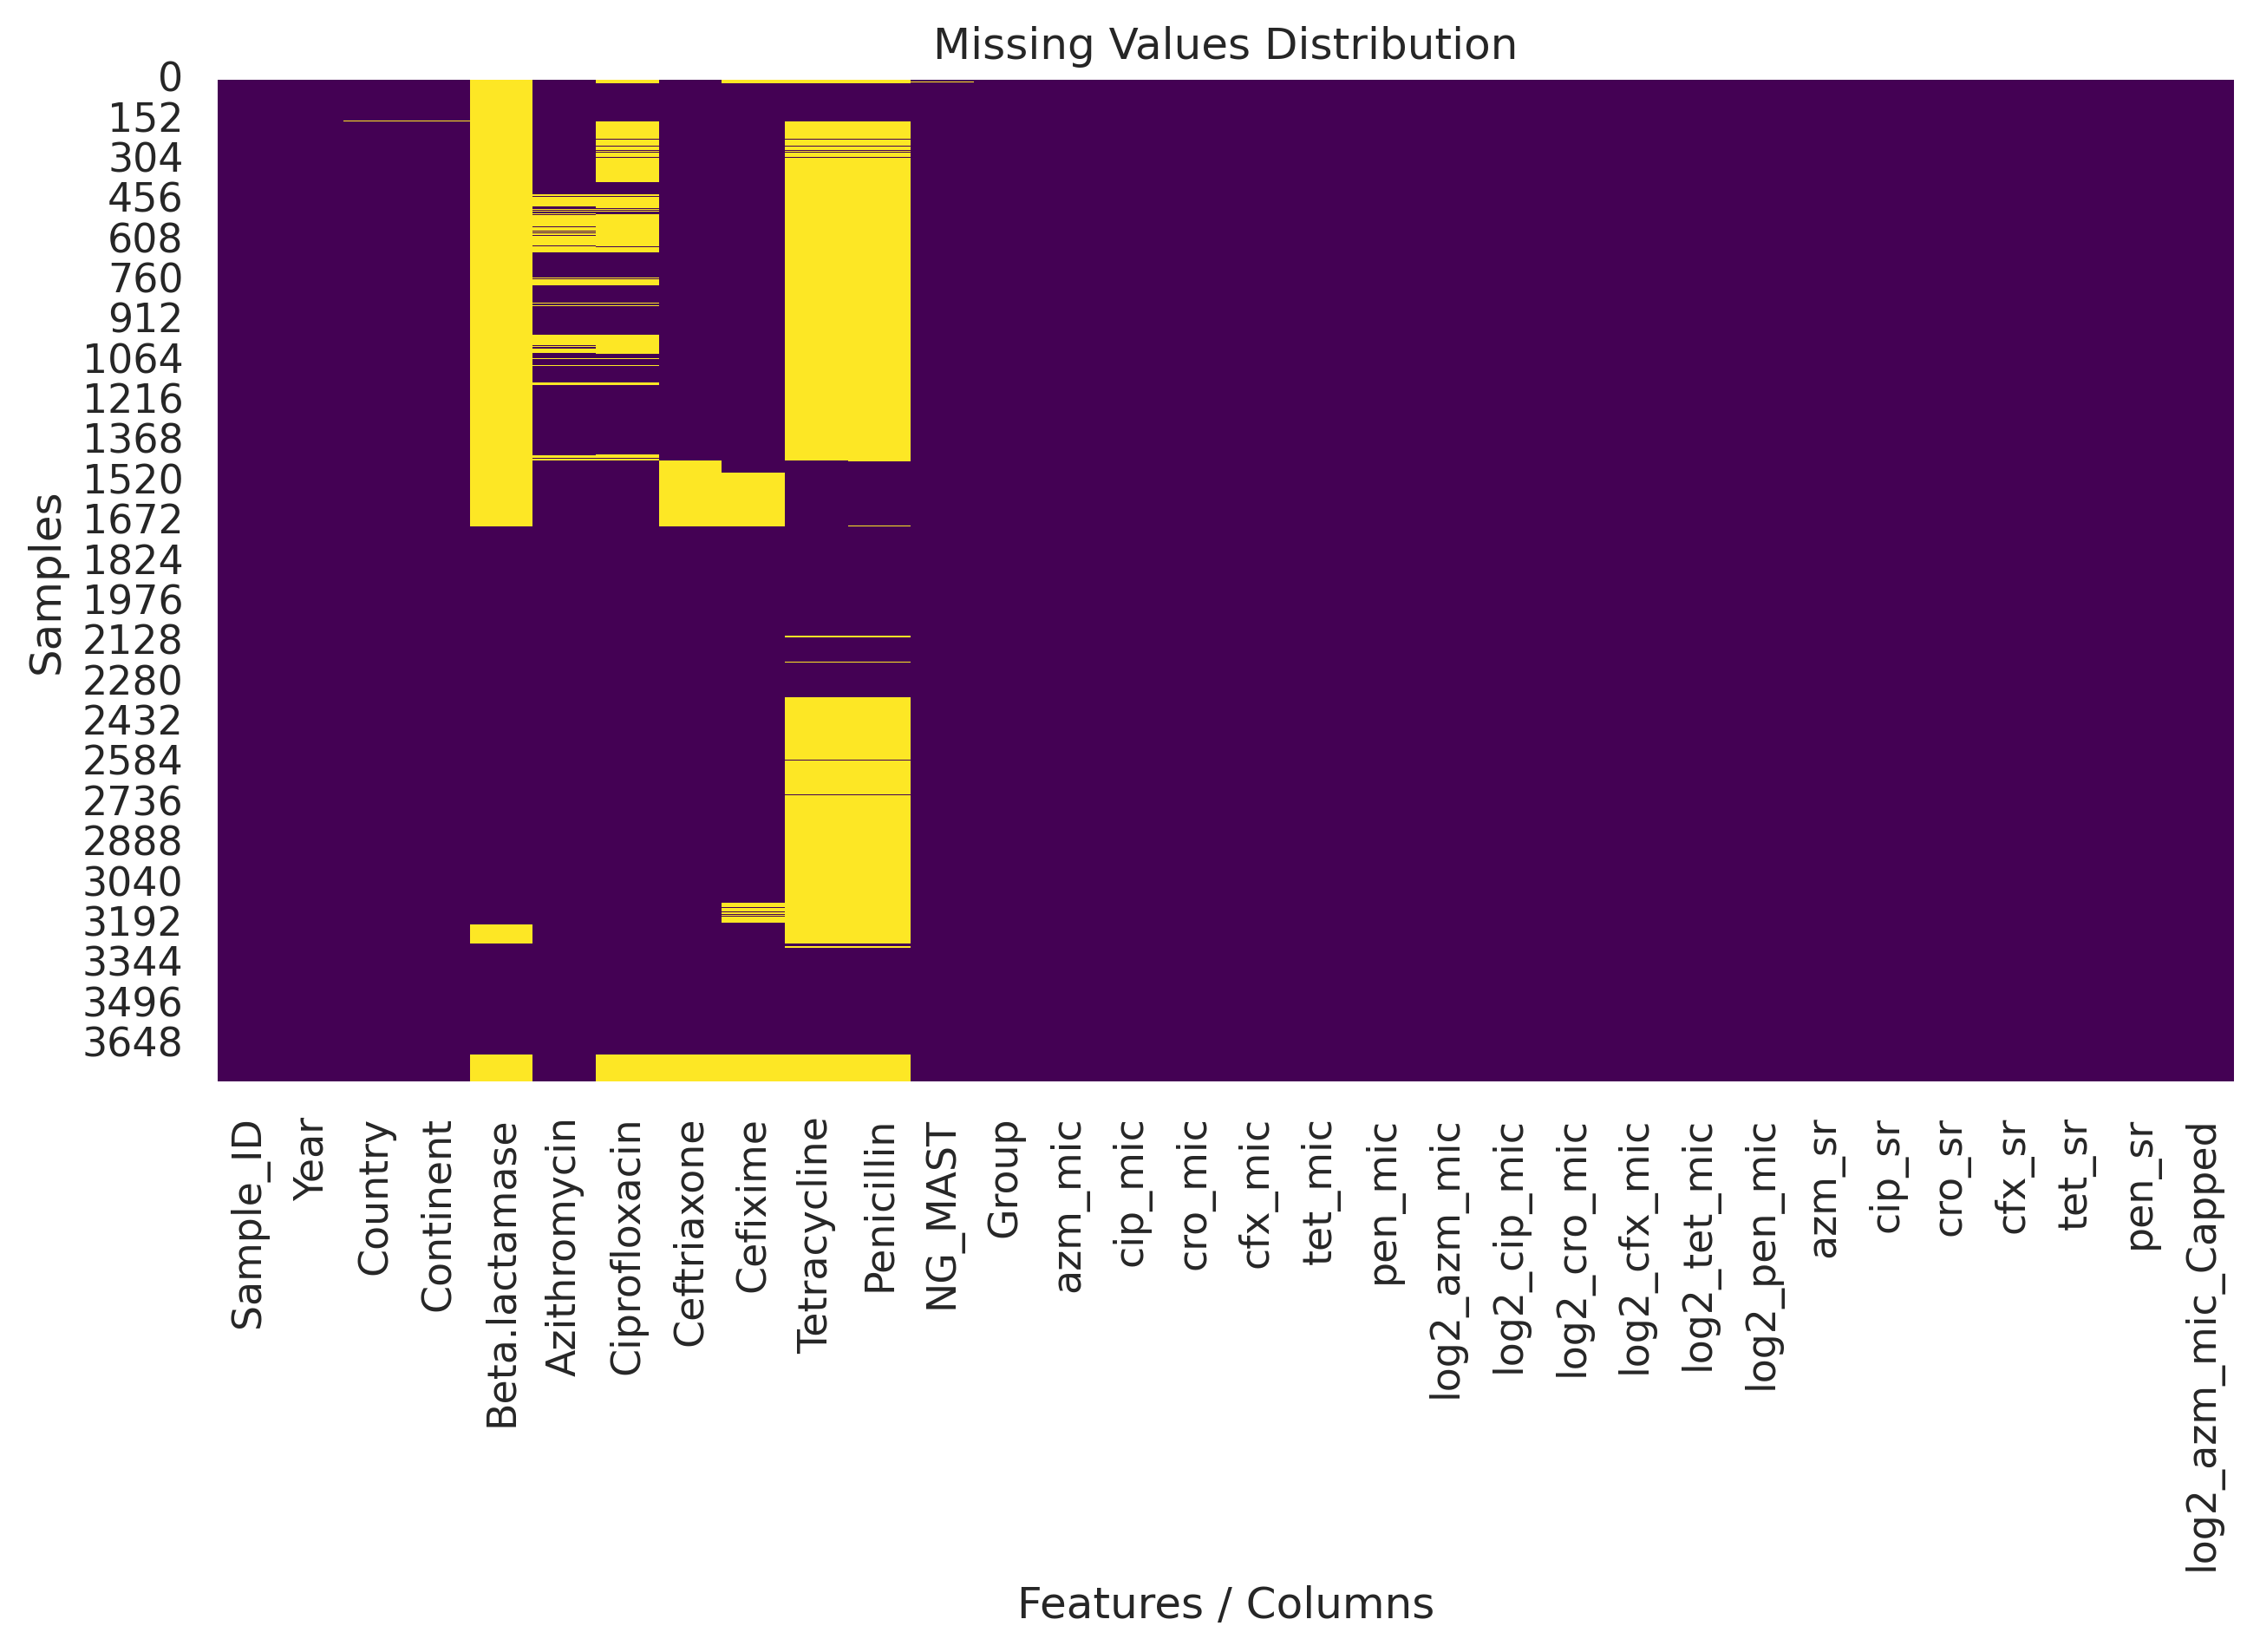

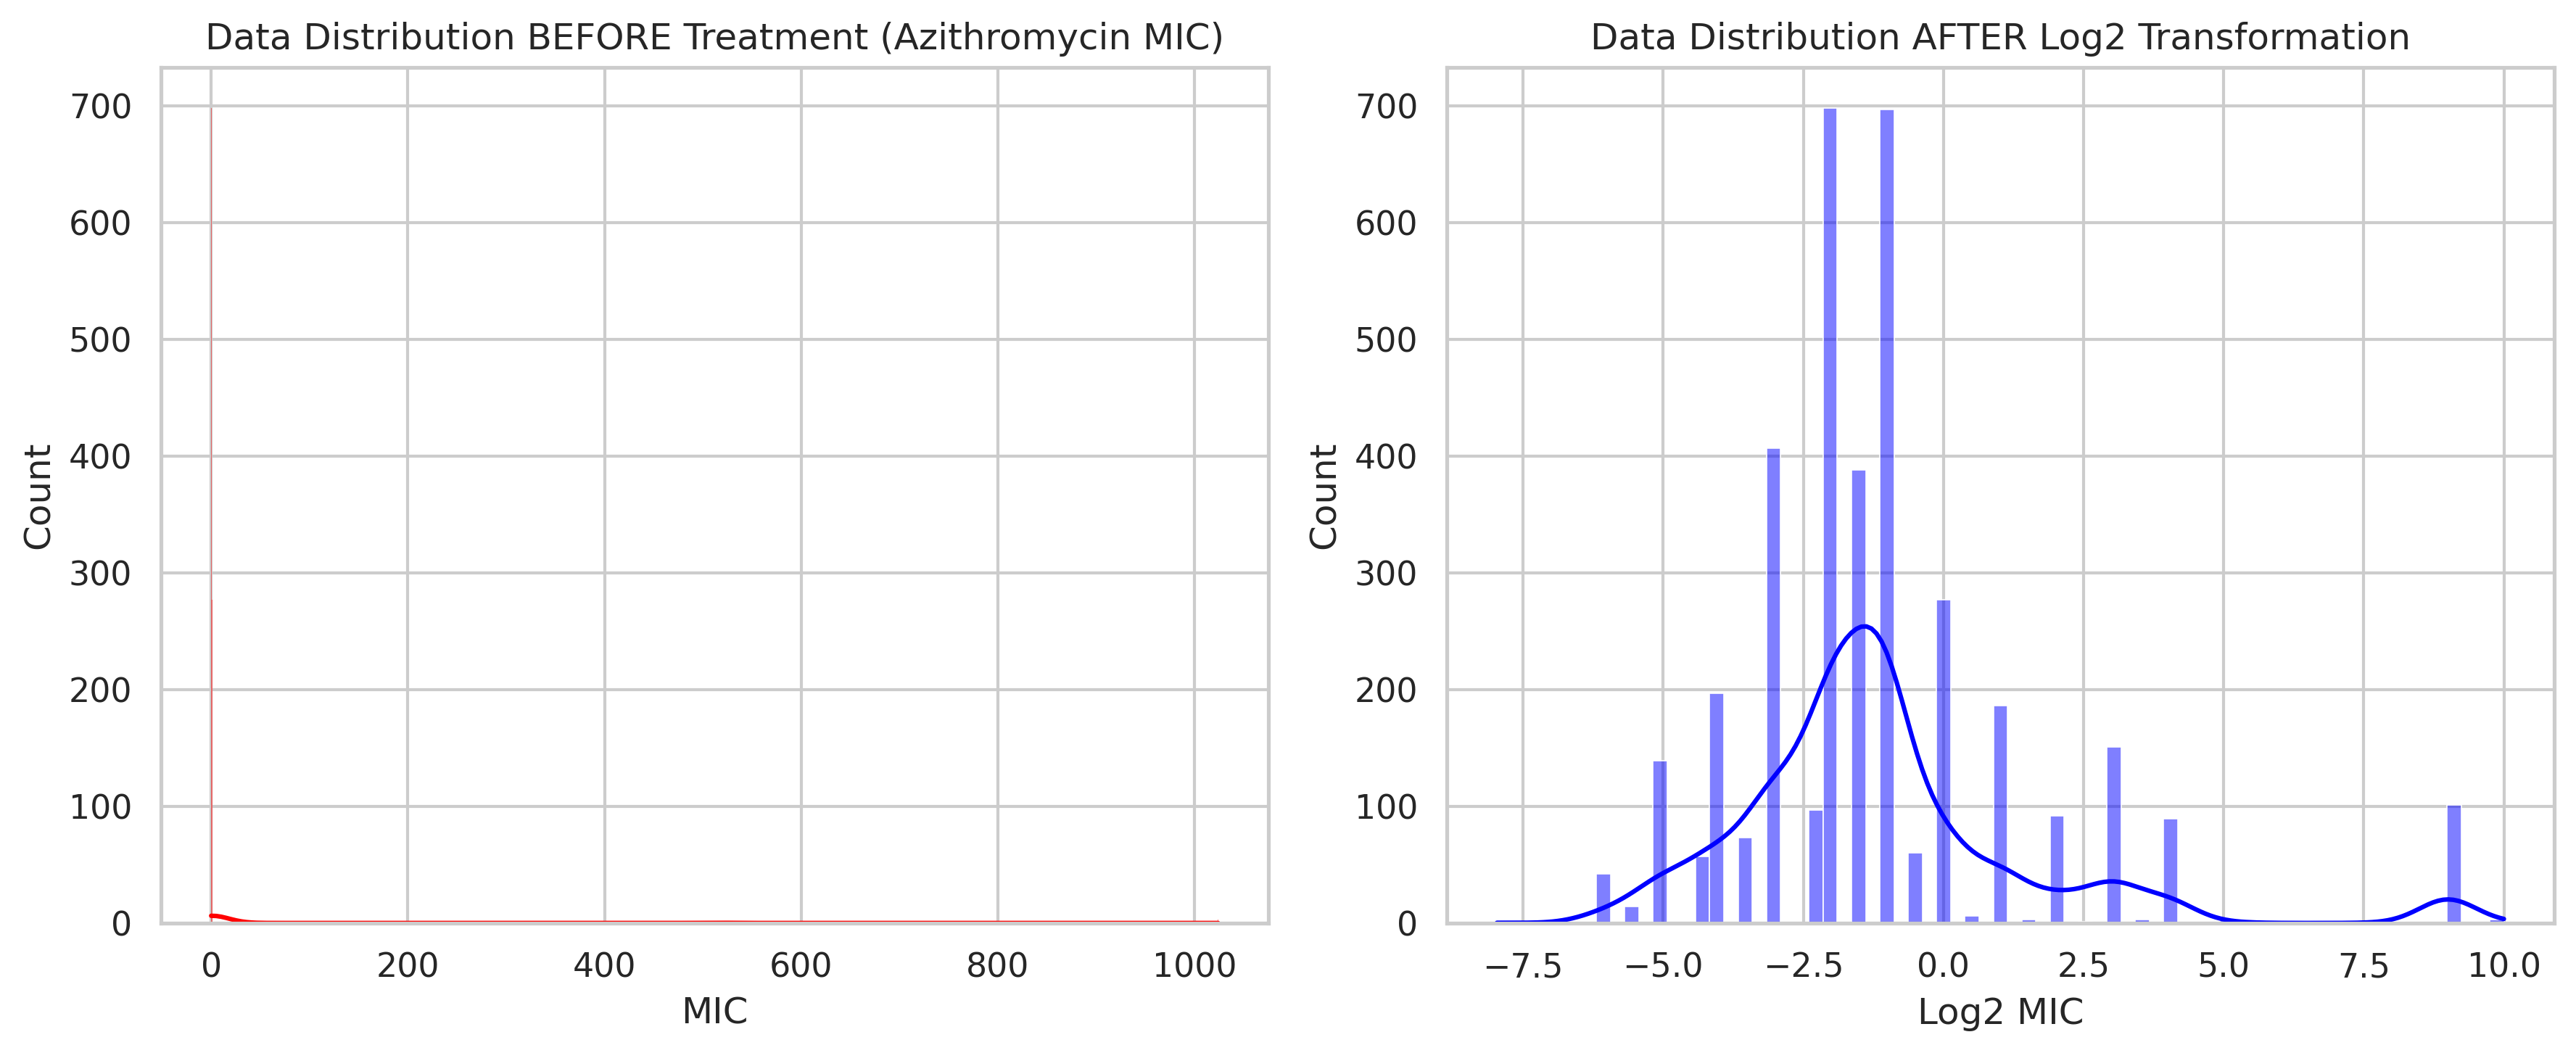

In [35]:
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis')
plt.title('Missing Values Distribution')
plt.xlabel('Features / Columns')
plt.ylabel('Samples')
plt.show()

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(df['azm_mic'], kde=True, color='red')
plt.title('Data Distribution BEFORE Treatment (Azithromycin MIC)')
plt.xlabel('MIC')

plt.subplot(1, 2, 2)
sns.histplot(df['log2_azm_mic'], kde=True, color='blue')
plt.title('Data Distribution AFTER Log2 Transformation')
plt.xlabel('Log2 MIC')

plt.tight_layout()
plt.show()

## 5. Unsupervised Clustering & Dimensionality Reduction
Applying the Elbow Method to determine the optimal number of clusters ($K$), executing K-Means clustering, and performing Principal Component Analysis (PCA) for dimensionality reduction and pattern discovery.

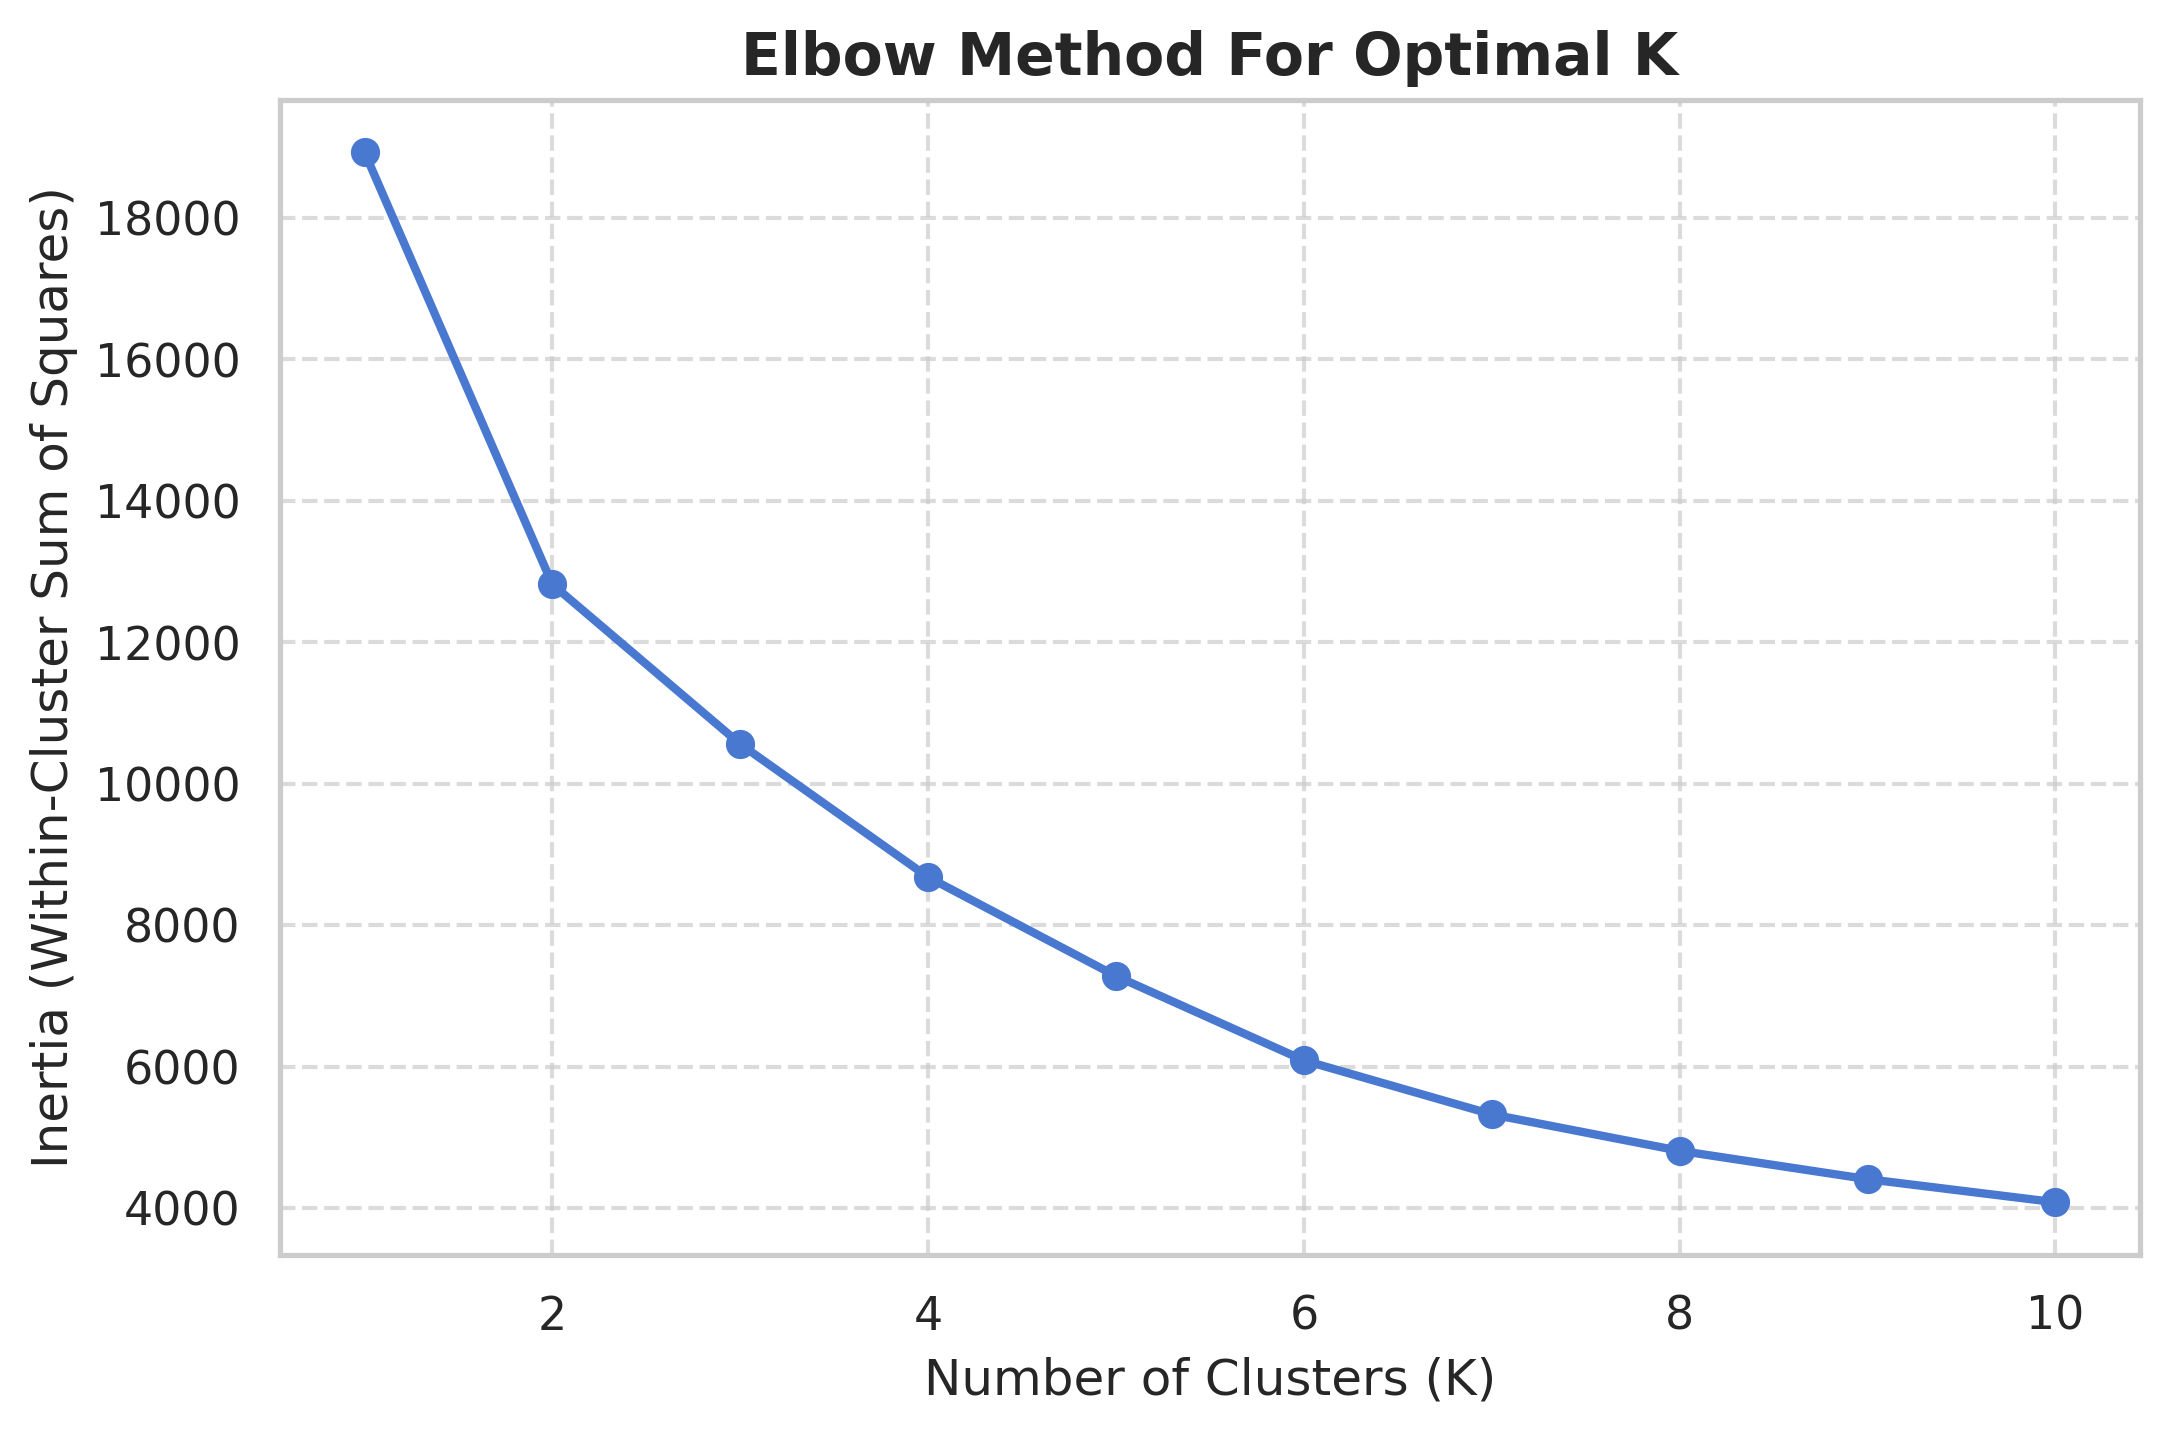

In [37]:
inertia = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(scaled_data)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K_range, inertia, marker='o', linestyle='-', color='b', linewidth=2)
plt.title('Elbow Method For Optimal K', fontsize=14, fontweight='bold')
plt.xlabel('Number of Clusters (K)', fontsize=12)
plt.ylabel('Inertia (Within-Cluster Sum of Squares)', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

In [38]:
pca = PCA(n_components=2)
pca_coords = pca.fit_transform(scaled_data)
df['PCA1'] = pca_coords[:, 0]
df['PCA2'] = pca_coords[:, 1]

In [39]:
kmeans = KMeans(n_clusters=3, random_state=42)
df['Cluster'] = kmeans.fit_predict(scaled_data)
print("تمت عمليات التطبيع، PCA، وتصنيف الكلاسترات (K-Means) بنجاح!")

تمت عمليات التطبيع، PCA، وتصنيف الكلاسترات (K-Means) بنجاح!


## 6. Results & Visualizations
Generating correlation heatmaps for Log2 MIC values to evaluate cross-resistance patterns, alongside geographical/continental distribution plots of resistance profiles.


--- جاري توليد الرسومات البيانية ---


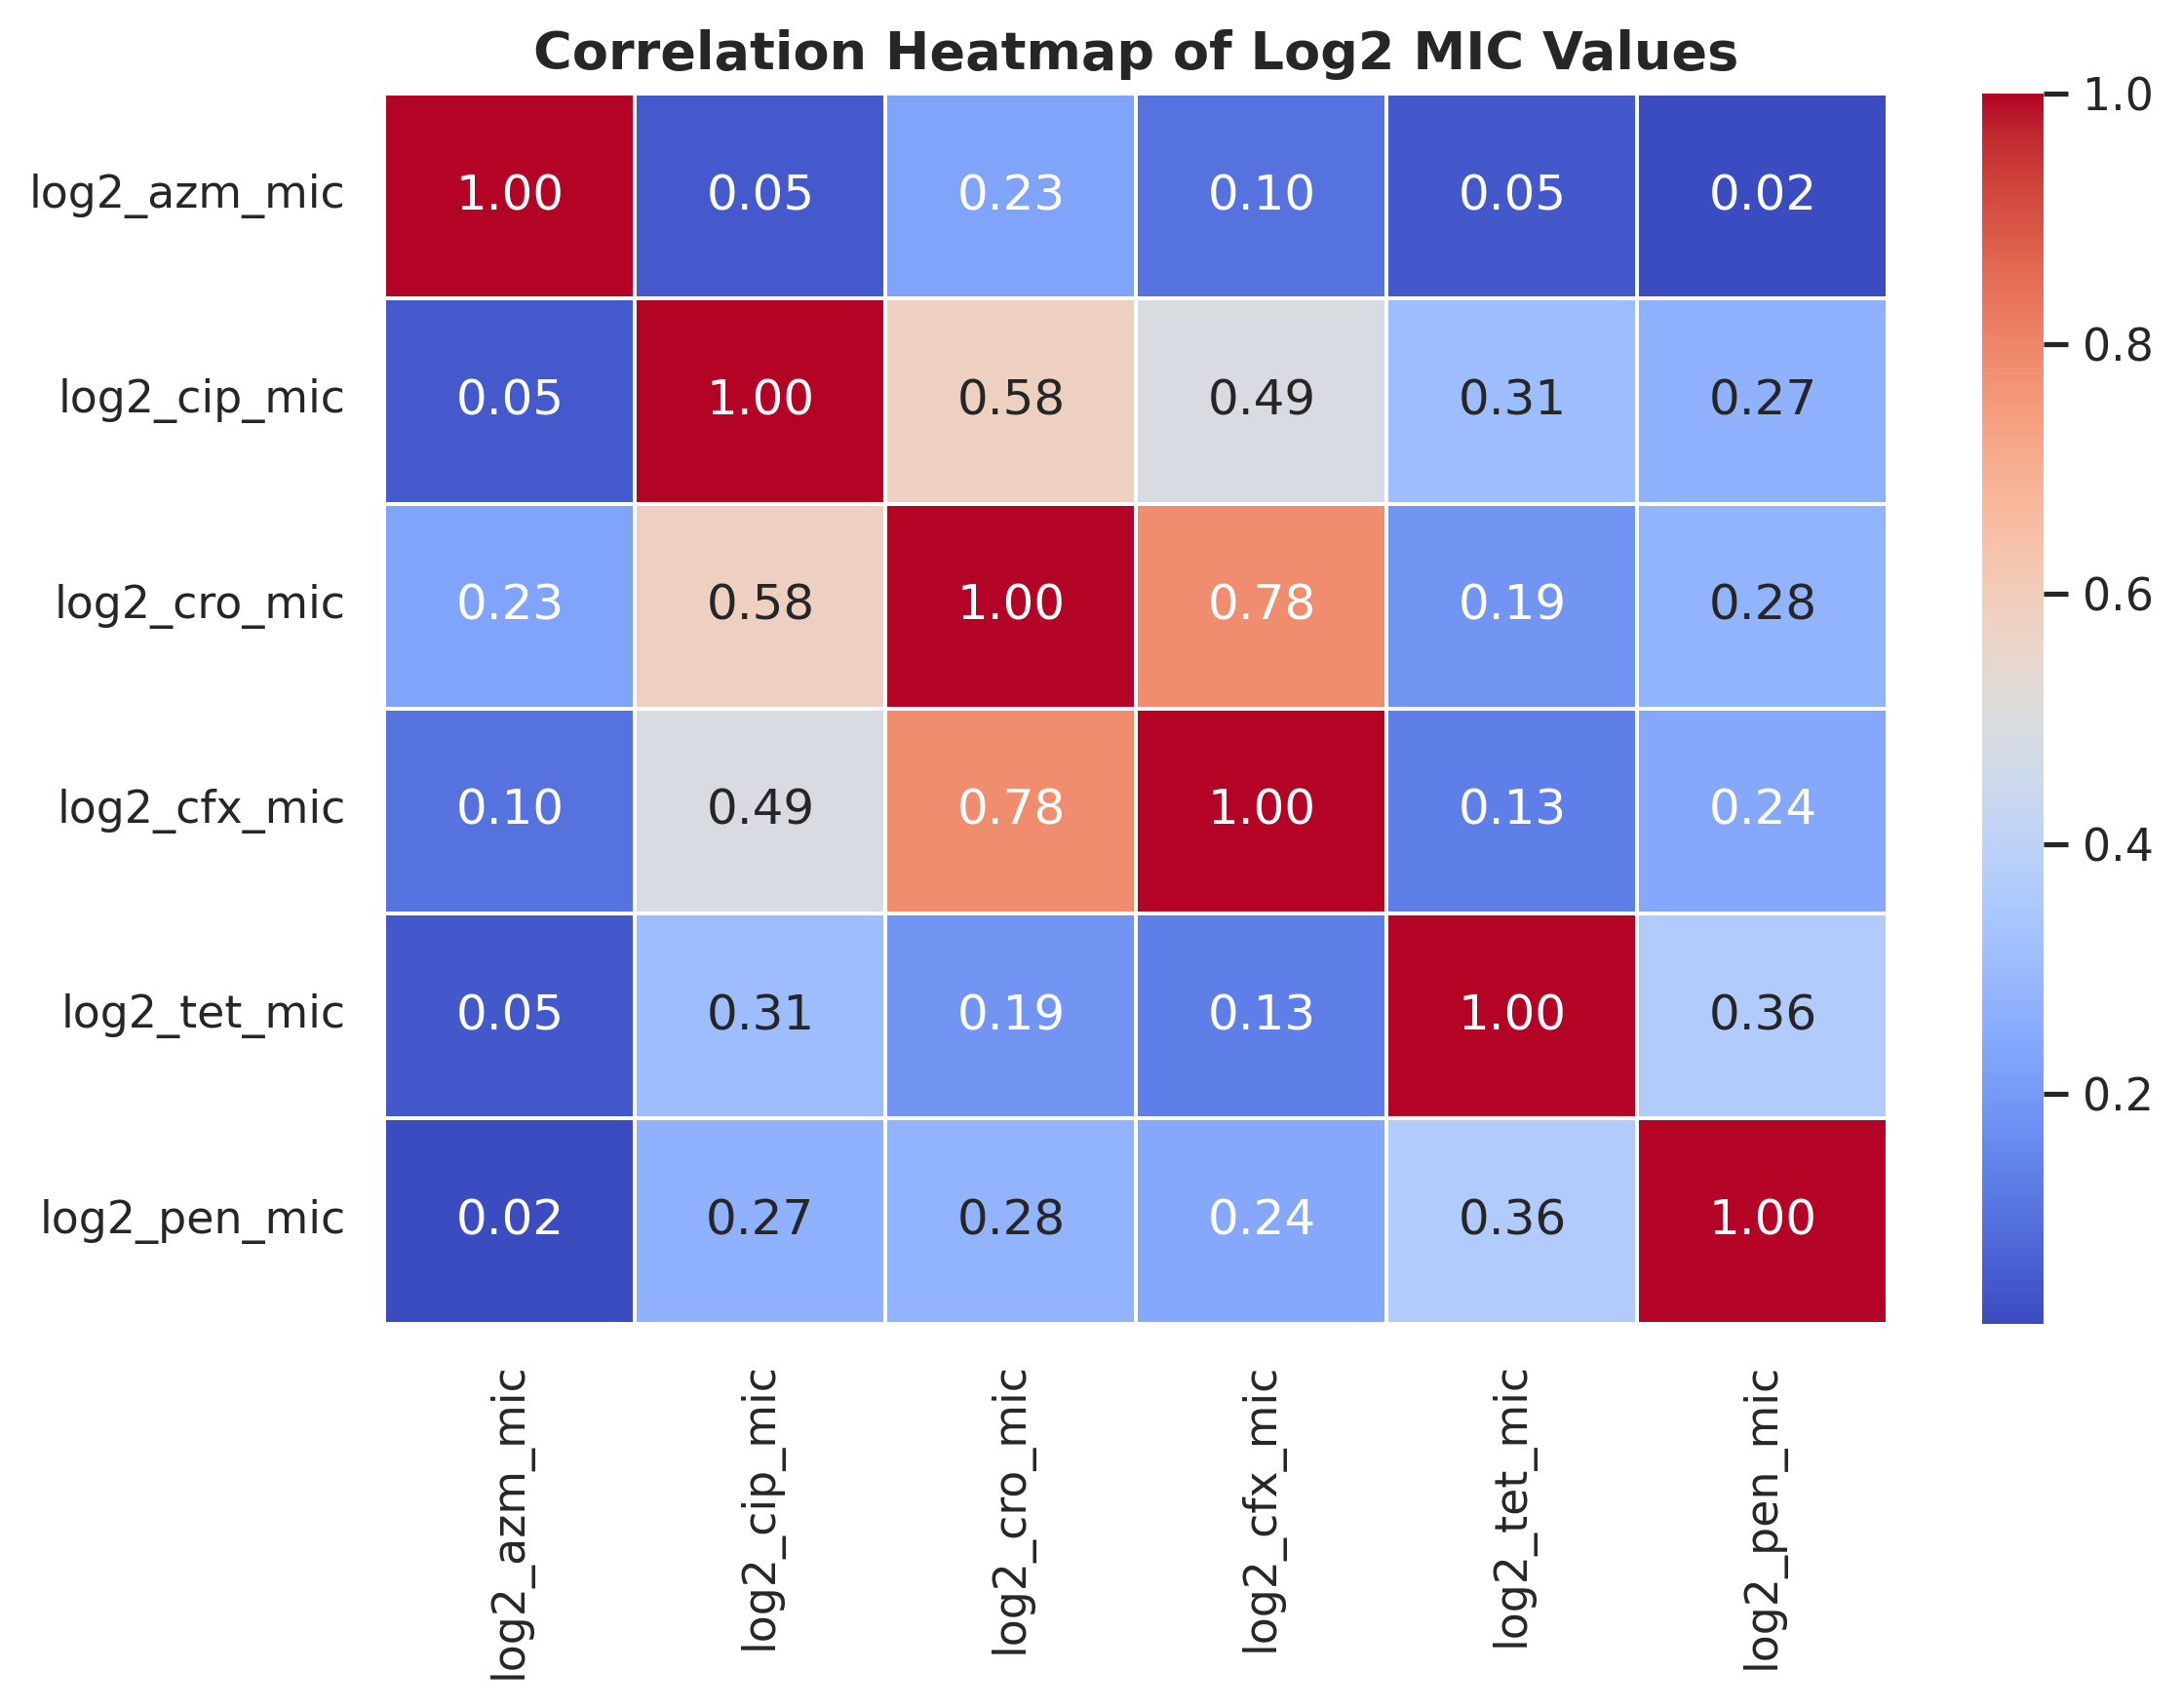

In [40]:
print("\n--- جاري توليد الرسومات البيانية ---")
if len(mic_log_cols) > 1:
    plt.figure(figsize=(8, 6))
    sns.heatmap(df[mic_log_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
    plt.title('Correlation Heatmap of Log2 MIC Values', fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.savefig('fig1_amr_heatmap.png')
    plt.show()

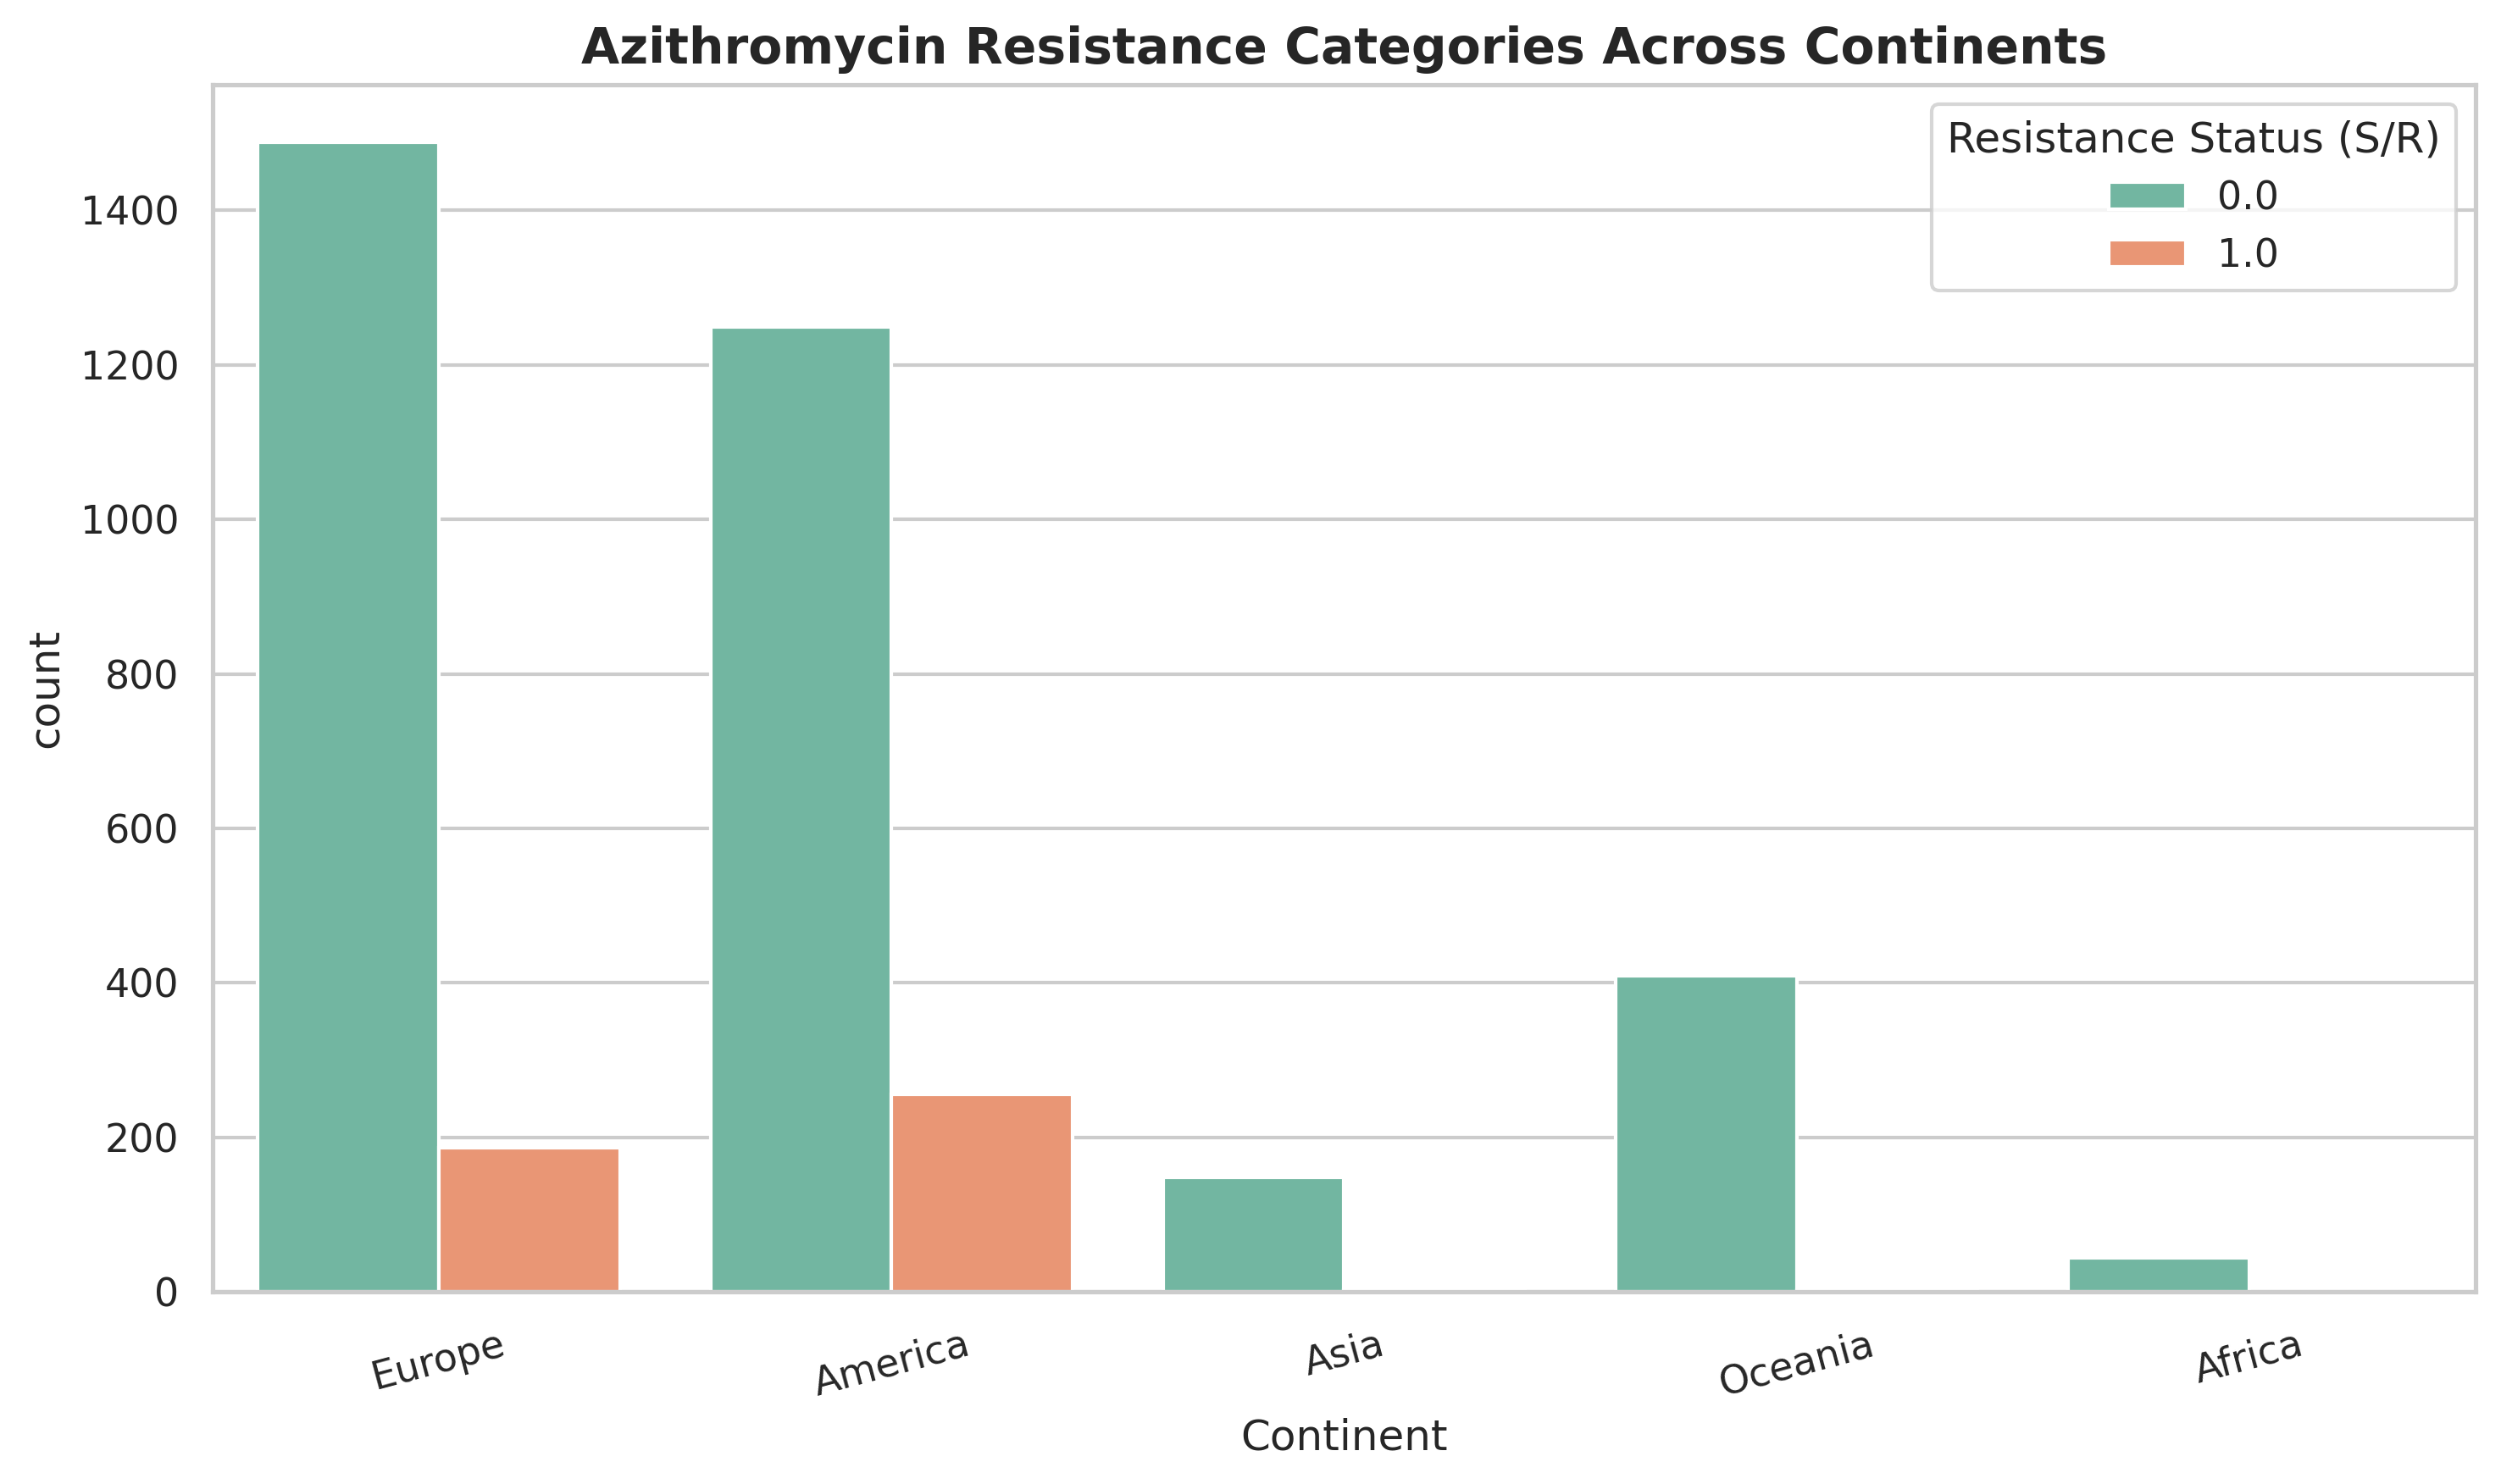

In [41]:
plt.figure(figsize=(10, 6))

if 'azm_sr' in df.columns:
    sns.countplot(data=df, x='Continent', hue='azm_sr', palette='Set2')
    plt.title('Azithromycin Resistance Categories Across Continents', fontsize=14, fontweight='bold')
    plt.legend(title='Resistance Status (S/R)', loc='upper right')
else:
    sns.boxplot(data=df, x='Continent', y='log2_azm_mic', palette='Set2')
    plt.title('Log2 Azithromycin MIC Distribution Across Continents', fontsize=14, fontweight='bold')
    plt.ylabel('Log2 Azithromycin MIC', fontsize=12)

plt.xlabel('Continent', fontsize=12)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig('fig2_fixed_resistance.png')
plt.show()

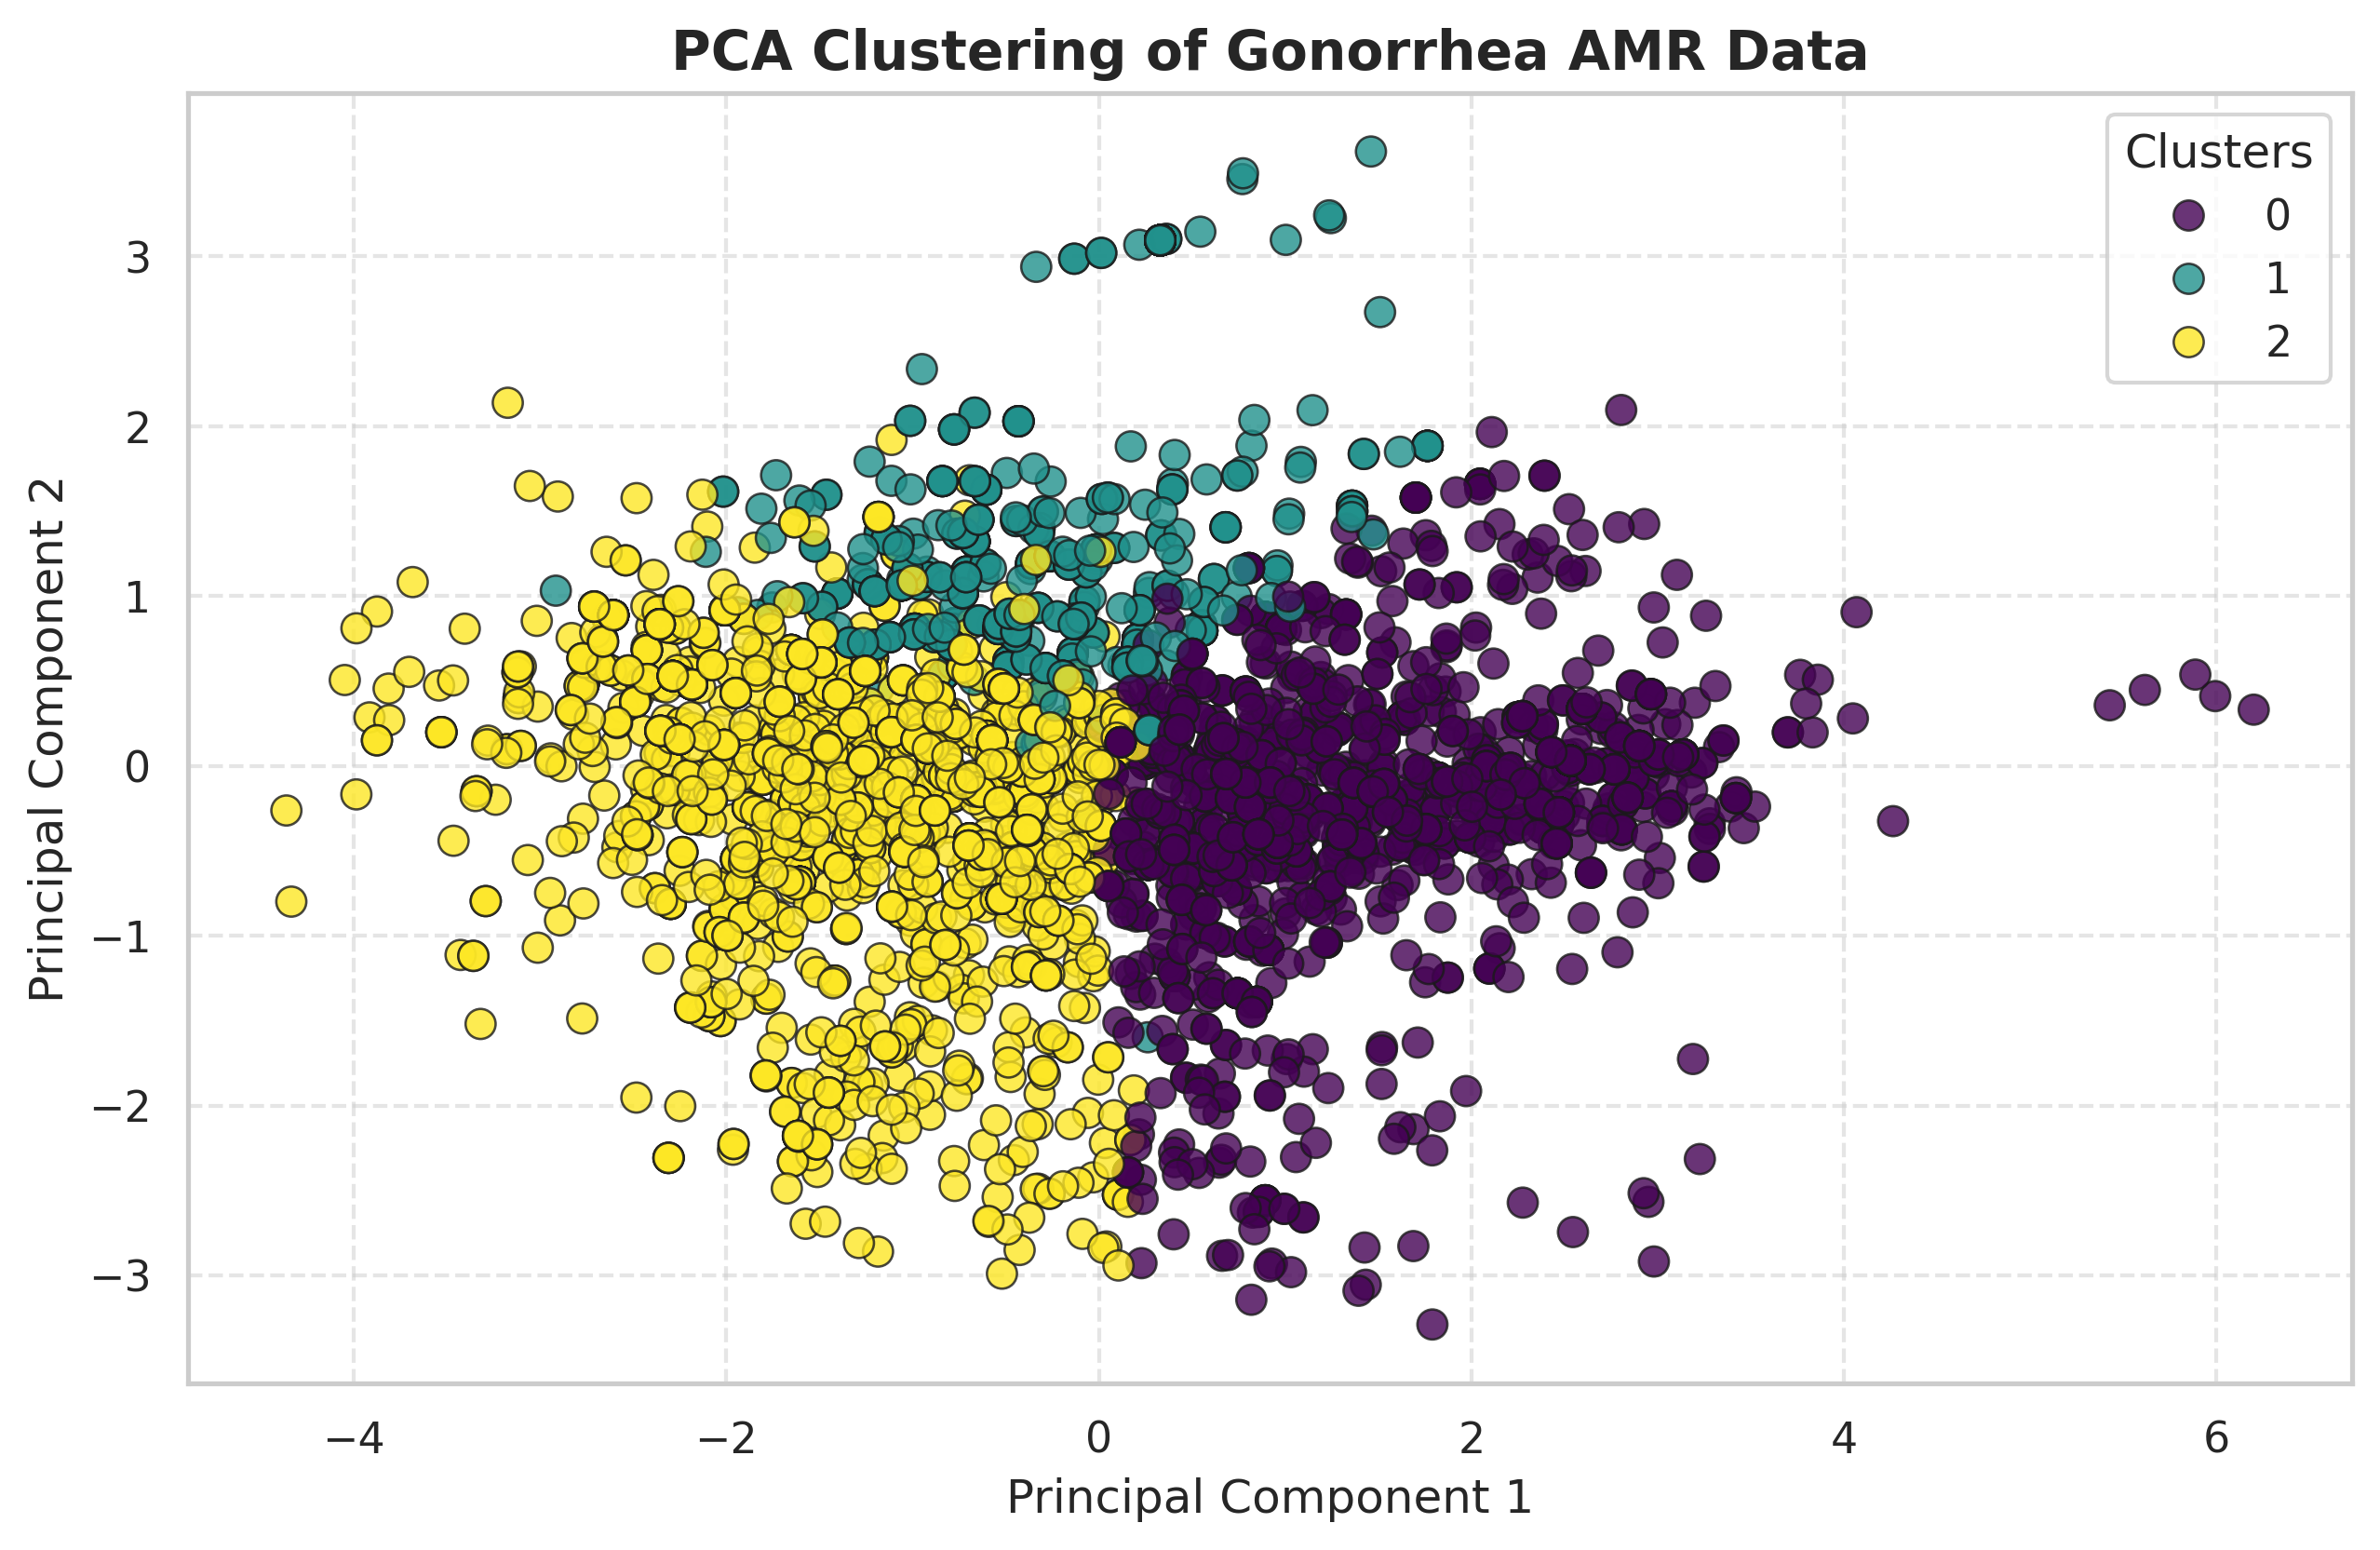

In [42]:
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x=pca_coords[:, 0], y=pca_coords[:, 1],
    hue=df['Cluster'], palette='viridis', s=60, alpha=0.8, edgecolor='k'
)
plt.title('PCA Clustering of Gonorrhea AMR Data', fontsize=14, fontweight='bold')
plt.xlabel('Principal Component 1', fontsize=12)
plt.ylabel('Principal Component 2', fontsize=12)
plt.legend(title='Clusters')
plt.grid(True, linestyle='--', alpha=0.5)
plt.savefig('pca_clusters_plot.png', dpi=300, bbox_inches='tight')
plt.show()